# 📓 02. Data Cleaning & Advanced Feature Engineering
> **Đề tài:** Phân tích Không gian - Kinh tế thị trường phòng trọ TP.HCM & Bình Dương (IE313)  

---
## 🎯 Mục tiêu Notebook:
1. Thực thi quy trình làm sạch 5 tầng (**5-Tier Cleaning Pipeline**): Khử trùng lặp kép, Domain Sanity, Grouped IQR theo Quận, và Điền khuyết.
2. Trực quan hóa so sánh phân phối **Before vs. After** khi áp dụng Grouped IQR.
3. Trích xuất đặc trưng văn bản (**NLP Regex**) và tính khoảng cách không gian (**Haversine Distance**).
4. Phân loại người đăng (**Seller Profiling**) và phân khúc thị trường (**K-Means Clustering**).

In [1]:
import json
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import sys
BASE_DIR = Path('..').resolve()
sys.path.append(str(BASE_DIR))

from src.cleaner import clean_rental_dataset
from src.features import build_feature_pipeline

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

## 1. Chạy Pipeline Làm sạch & Biểu đồ Phễu lọc dữ liệu (Data Funnel)

[13:46:49] INFO - Loading interim data from D:\UIT\FOUNDATIONAL SUBJECTS\IE313-Phân tích và trực quan dữ liệu\ĐỒ ÁN\data\interim\deduplicated_data.parquet...


[13:46:49] INFO - [0_RawInput] Remaining: 7046 listings | Description: Dữ liệu thô ban đầu thu thập từ API Chợ Tốt


[13:46:50] INFO - [1a_DedupAdId] Remaining: 7046 listings | Description: Khử trùng lặp khóa chính ad_id


[13:46:50] INFO - [1b_DedupBrokerSpam] Remaining: 6807 listings | Description: Khử trùng lặp spam môi giới cùng phòng đăng nhiều lần


[13:46:50] INFO - [2_DomainSanity] Remaining: 6611 listings | Description: Lọc miền hợp lệ: Giá [0.5, 25.0] tr, Diện tích [5.0, 120.0] m²


[13:46:50] INFO - [3_GroupedIQROutliers] Remaining: 6324 listings | Description: Lọc ngoại lai đơn giá (price_per_m2_k) theo phương pháp Grouped IQR từng Quận


[13:46:50] INFO - [4_MissingImputed] Remaining: 6324 listings | Description: Điền khuyết tiền cọc (theo tỷ lệ Quận) và tọa độ địa lý (theo tâm Phường)


[13:46:50] INFO - Audit report saved to D:\UIT\FOUNDATIONAL SUBJECTS\IE313-Phân tích và trực quan dữ liệu\ĐỒ ÁN\data\processed\data_audit_report.json


,step,count,dropped,retention_pct,description
0,0_RawInput,7046,0,100.00,Dữ liệu thô ban đầu thu thập từ API Chợ Tốt
1,1a_DedupAdId,7046,0,100.00,Khử trùng lặp khóa chính ad_id
2,1b_DedupBrokerSpam,6807,239,96.61,Khử trùng lặp spam môi giới cùng phòng đăng nh...
3,2_DomainSanity,6611,196,93.83,"Lọc miền hợp lệ: Giá [0.5, 25.0] tr, Diện tích..."
4,3_GroupedIQROutliers,6324,287,89.75,Lọc ngoại lai đơn giá (price_per_m2_k) theo ph...
5,4_MissingImputed,6324,0,89.75,Điền khuyết tiền cọc (theo tỷ lệ Quận) và tọa ...


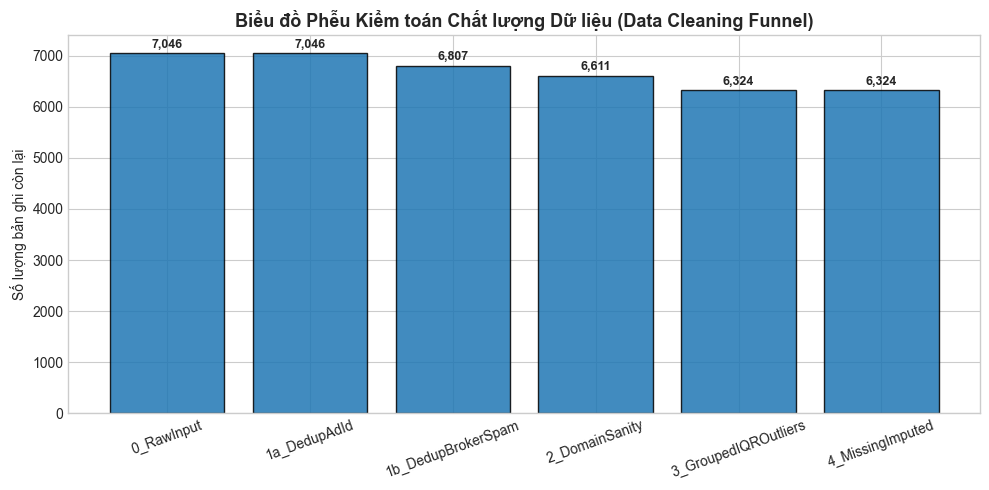

In [2]:
df_cleaned, audit_report = clean_rental_dataset()

funnel_df = pd.DataFrame(audit_report['funnel_steps'])
display(funnel_df[['step', 'count', 'dropped', 'retention_pct', 'description']])

# Trực quan hóa Data Funnel
plt.figure(figsize=(10, 5))
bars = plt.bar(funnel_df['step'], funnel_df['count'], color='#1f77b4', edgecolor='black', alpha=0.85)
plt.title('Biểu đồ Phễu Kiểm toán Chất lượng Dữ liệu (Data Cleaning Funnel)', fontsize=13, fontweight='bold')
plt.ylabel('Số lượng bản ghi còn lại')
plt.xticks(rotation=20)
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 50, f'{int(yval):,}', ha='center', va='bottom', fontsize=9, fontweight='bold')
plt.tight_layout()
plt.show()

## 2. Trích xuất Đặc trưng Nâng cao (Feature Engineering)
- **NLP Regex:** `has_mezzanine`, `has_ac`, `is_free_curfew`, `has_balcony_window`
- **Geospatial:** `dist_to_q1_km`, `dist_to_vnuhcm_km`
- **Behavioral:** `seller_type` (Chính chủ vs Môi giới trá hình)
- **Clustering:** `market_cluster` (Tier 1, Tier 2, Tier 3)

In [3]:
df_features = build_feature_pipeline(df_cleaned)
display(df_features.head(3))

# Thống kê tỷ lệ các tiện ích
amenities = ['has_ac', 'has_mezzanine', 'is_free_curfew', 'has_balcony_window']
amenity_pct = (df_features[amenities].mean() * 100).round(1)
print('Tỷ lệ phòng có tiện ích (%):\n', amenity_pct)

[13:46:50] INFO - Extracting NLP regex amenity features from title and body...


[13:46:50] INFO - Feature [has_mezzanine]: 1564 listings (24.7%) positive.


[13:46:50] INFO - Feature [has_ac]: 2447 listings (38.7%) positive.


[13:46:50] INFO - Feature [is_free_curfew]: 3500 listings (55.3%) positive.


[13:46:50] INFO - Feature [has_balcony_window]: 3159 listings (50.0%) positive.


[13:46:50] INFO - Calculating Haversine geospatial distances...


... (10 outputs left out)

[13:46:52] INFO - Market Cluster Breakdown:
market_cluster
Tier 3: Studio/Căn hộ dịch vụ    2449
Tier 1: Sinh viên/Bình dân       2358
Tier 2: Tiện nghi tầm trung      1517
Name: count, dtype: int64


[13:46:53] INFO - Saved full cleaned & featured dataset (6324 rows) to D:\UIT\FOUNDATIONAL SUBJECTS\IE313-Phân tích và trực quan dữ liệu\ĐỒ ÁN\data\processed\rental_cleaned_full.csv.


,account_id,account_name,account_oid,ad_features,ad_id,ad_labels,area,area_name,area_v2,avatar,...,seller_rating,seller_n_ratings,body_length,is_shared_or_dorm,area_group,account_ad_count,account_n_areas,is_company,seller_type,market_cluster
6842,9482629,Lê Minh Tú,ad63b78008055fbf4525b8ce01ef808b,[],176221237,[],11,Huyện Bàu Bàng,201102,https://cdn.chotot.com/uac2/9482629,...,NaN,0,233,0,Bình Dương - Khác,1,1,False,Chính chủ,Tier 1: Sinh viên/Bình dân
2202,21696436,Yenny Du,085518b52336b9516b6cc8440892e95d,[],180015358,[],115,Huyện Bình Chánh,13115,https://cdn.chotot.com/uac2/21696436,...,NaN,0,89,0,Huyện Bình Chánh,1,1,False,Chính chủ,Tier 1: Sinh viên/Bình dân
2203,4185463,Phước Thiện,ceac629cac2eb67ad5be2cef2acd0c5f,[],175336157,[],115,Huyện Bình Chánh,13115,https://cdn.chotot.com/uac2/4185463,...,5.0,5,525,1,Huyện Bình Chánh,3,3,True,Môi giới công khai,Tier 1: Sinh viên/Bình dân


Tỷ lệ phòng có tiện ích (%):
 has_ac                38.7
has_mezzanine         24.7
is_free_curfew        55.3
has_balcony_window    50.0
dtype: float64
